# 10 · Final submission, required baselines, reporting outputs
Reads saved Step 08/09 outputs only — no retraining, no re-solving. Writes `policy_submission.csv` (exact 4-column schema),
the three required baseline policies scored with the same July predictions/costs, and memo/deck/dashboard tables & figures.

## Load data + constants

In [1]:
import sys, math
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.common import ROOT, TABLES, FIGS, load_clean, load_processed
from src.modeling import ACTIONS, COMMERCIAL
pd.set_option("display.width", 200)
FINAL = ROOT / "outputs" / "final"; FINAL.mkdir(exist_ok=True)
vals = pd.read_csv(TABLES / "july_customer_action_values.csv")
pol = pd.read_csv(TABLES / "optimized_policy_detailed.csv")
hold_ids = set(pd.read_csv(TABLES / "measurement_holdout.csv").customer_id)
ps = load_clean(["policy_scoring_population"])["policy_scoring_population"]
hist = load_processed("historical_feature_outcome")
BUDGET, MAX_OFFER_SHARE, MAX_PCT20_SHARE, HOLDOUT_SHARE = 62_000, 0.60, 0.15, 0.05
N = len(ps); MAX_OFFERS = math.floor(MAX_OFFER_SHARE * N)
V = vals.set_index(["customer_id", "action"])
COLORS = dict(zip(ACTIONS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))

## A. Exact final submission + checks (fail loudly)

In [2]:
SUB_COLS = ["customer_id", "recommended_action", "estimated_incremental_ncm", "estimated_promo_cost"]
sub = pol[SUB_COLS].sort_values("customer_id").reset_index(drop=True)
sub[["estimated_incremental_ncm", "estimated_promo_cost"]] = sub[["estimated_incremental_ncm", "estimated_promo_cost"]].round(4)
n_off = sub.recommended_action.ne("NO_OFFER").sum(); n20 = sub.recommended_action.eq("PCT_20").sum()
ref = V.loc[list(zip(sub.customer_id, sub.recommended_action)), ["estimated_incremental_ncm", "estimated_promo_cost"]].to_numpy()
checks = {
    "exact columns / order": list(sub.columns) == SUB_COLS,
    "every scoring customer exactly once": len(sub) == N and sub.customer_id.is_unique and set(sub.customer_id) == set(ps.customer_id),
    "valid, non-missing actions": sub.recommended_action.isin(ACTIONS).all(),
    "finite incremental NCM and promo cost": np.isfinite(sub[["estimated_incremental_ncm", "estimated_promo_cost"]].to_numpy()).all(),
    "promo cost >= 0": (sub.estimated_promo_cost >= 0).all(),
    "expected promo spend <= $62,000": sub.estimated_promo_cost.sum() <= BUDGET,
    "offered share <= 60%": n_off <= MAX_OFFERS,
    "PCT_20 share among offered <= 15%": n20 <= MAX_PCT20_SHARE * n_off + 1e-9,
    "all reserved holdout customers NO_OFFER": sub[sub.customer_id.isin(hold_ids)].recommended_action.eq("NO_OFFER").all(),
    "reserved holdout >= 5%": len(hold_ids) >= math.ceil(HOLDOUT_SHARE * N),
    "values match Step 09 selected rows": np.allclose(sub[["estimated_incremental_ncm", "estimated_promo_cost"]].to_numpy(), ref, atol=1e-4)}
print(pd.Series(checks).to_string()); assert all(checks.values()), checks
sub.to_csv(ROOT / "policy_submission.csv", index=False)
sub.to_csv(FINAL / "policy_submission.csv", index=False)
print(sub.shape, list(sub.columns))

exact columns / order                      True
every scoring customer exactly once        True
valid, non-missing actions                 True
finite incremental NCM and promo cost      True
promo cost >= 0                            True
expected promo spend <= $62,000            True
offered share <= 60%                       True
PCT_20 share among offered <= 15%          True
all reserved holdout customers NO_OFFER    True
reserved holdout >= 5%                     True
values match Step 09 selected rows         True
(2776, 4) ['customer_id', 'recommended_action', 'estimated_incremental_ncm', 'estimated_promo_cost']


## B. Required baseline policies (same July predictions and costs)
1. **ALL_NO_OFFER.** 2. **PROPENSITY_PCT10**: holdout kept NO_OFFER; remaining customers ranked by Logistic propensity; PCT_10 while
budget and 60% cap allow. 3. **HISTORICAL_MIX**: business_rule commercial mix (PCT_10/PCT_20/FREE_SHIP) applied to a seeded random
60% of non-holdout customers (historical offer rate 74.8% exceeds the cap, so the offer count is scaled to the cap).

In [3]:
base = vals.query("action == 'NO_OFFER'")[["customer_id", "predicted_purchase_probability"]].set_index("customer_id")
p1 = pd.Series("NO_OFFER", index=base.index)
p2, spend, k = p1.copy(), 0.0, 0
for cid in base.drop(index=list(hold_ids)).sort_values("predicted_purchase_probability", ascending=False, kind="mergesort").index:
    c = V.at[(cid, "PCT_10"), "estimated_promo_cost"]
    if k < MAX_OFFERS and spend + c <= BUDGET:
        p2[cid], spend, k = "PCT_10", spend + c, k + 1
br = hist.loc[hist.assignment_source == "business_rule", "offer_type"]
mix = br[br != "NO_OFFER"].value_counts(normalize=True).reindex(COMMERCIAL)
raw = mix * MAX_OFFERS
counts = np.floor(raw).astype(int); counts[(raw - counts).sort_values(ascending=False).index[: MAX_OFFERS - counts.sum()]] += 1
elig = np.random.default_rng(42).permutation(np.sort(base.drop(index=list(hold_ids)).index.to_numpy()))
p3 = p1.copy(); p3[elig[:MAX_OFFERS]] = np.repeat(COMMERCIAL, counts.values)
while sum(V.at[(c, a), "estimated_promo_cost"] for c, a in p3[p3 != "NO_OFFER"].items()) > BUDGET:
    p3[p3[p3 != "NO_OFFER"].index[-1]] = "NO_OFFER"
p4 = pol.set_index("customer_id").recommended_action.reindex(base.index)
policies = {"ALL_NO_OFFER": p1, "PROPENSITY_PCT10": p2, "HISTORICAL_MIX": p3, "OPTIMIZED_MILP": p4}
print("historical business_rule commercial mix:", mix.round(3).to_dict(), "| HISTORICAL_MIX achieved:",
      p3[p3 != "NO_OFFER"].value_counts(normalize=True).reindex(COMMERCIAL).round(3).to_dict())

historical business_rule commercial mix: {'PCT_10': 0.598, 'PCT_20': 0.131, 'FREE_SHIP': 0.271} | HISTORICAL_MIX achieved: {'PCT_10': 0.598, 'PCT_20': 0.131, 'FREE_SHIP': 0.271}


## Comparison table

In [4]:
def evaluate(name, p):
    s = V.loc[list(zip(p.index, p.values))]
    n_o = int((p != "NO_OFFER").sum()); n_20 = int((p == "PCT_20").sum()); sp = s.estimated_promo_cost.sum(); inc = s.estimated_incremental_ncm.sum()
    return {"policy": name, "customers": len(p), **{f"n_{a}": int((p == a).sum()) for a in ACTIONS}, "offer_share": n_o / len(p),
            "pct20_share_among_offered": n_20 / n_o if n_o else 0.0, "expected_promo_spend": sp, "total_expected_ncm": s.predicted_ncm.sum(),
            "total_expected_incremental_ncm": inc, "incremental_ncm_per_customer": inc / len(p),
            "incremental_ncm_per_promo_dollar": inc / sp if sp > 0 else np.nan,
            "holdout_all_no_offer": bool((p[list(hold_ids)] == "NO_OFFER").all()),
            "within_all_constraints": sp <= BUDGET and n_o <= MAX_OFFERS and n_20 <= MAX_PCT20_SHARE * n_o + 1e-9}
cmp = pd.DataFrame([evaluate(k, v) for k, v in policies.items()])
cmp.to_csv(TABLES / "baseline_policy_comparison.csv", index=False)
pd.DataFrame(policies).rename_axis("customer_id").reset_index().to_csv(TABLES / "baseline_policy_assignments.csv", index=False)
cmp.set_index("policy").T.round(3)

policy,ALL_NO_OFFER,PROPENSITY_PCT10,HISTORICAL_MIX,OPTIMIZED_MILP
customers,2776,2776,2776,2776
n_NO_OFFER,2776,1111,1111,1111
n_PCT_10,0,1665,996,206
n_PCT_20,0,0,218,0
n_FREE_SHIP,0,0,451,1459
offer_share,0.0,0.599784,0.599784,0.599784
pct20_share_among_offered,0.0,0.0,0.130931,0.0
expected_promo_spend,0.0,7637.739718,6211.198222,1213.647123
total_expected_ncm,44834.515763,35865.483639,41323.280873,51241.420172
total_expected_incremental_ncm,0.0,-8969.032075,-3511.234878,6406.904365


## Reporting tables

In [5]:
fin = pol.merge(vals.pivot(index="customer_id", columns="action", values="predicted_ncm").add_prefix("predicted_ncm_"), on="customer_id")
fin = fin.merge(vals.pivot(index="customer_id", columns="action", values="estimated_incremental_ncm").add_prefix("incremental_ncm_"), on="customer_id")
fin = fin.merge(vals.pivot(index="customer_id", columns="action", values="estimated_promo_cost").add_prefix("promo_cost_"), on="customer_id")
jf = load_processed("july_features")
fin = fin.merge(jf[["customer_id", "customer_tier", "is_member", "region", "customer_tenure_days", "prior_order_count", "sessions_30d"]], on="customer_id")
fin.to_csv(TABLES / "customer_policy_audit.csv", index=False)
act = pol.groupby("recommended_action").agg(customers=("customer_id", "size"), expected_incremental_ncm=("estimated_incremental_ncm", "sum"),
                                            mean_incremental_ncm=("estimated_incremental_ncm", "mean"), expected_promo_spend=("estimated_promo_cost", "sum"),
                                            mean_purchase_probability=("predicted_purchase_probability", "mean"),
                                            holdout_customers=("measurement_holdout", "sum")).reindex(ACTIONS, fill_value=0)
act.insert(1, "share", act.customers / N)
act.rename_axis("action").to_csv(TABLES / "policy_action_summary.csv")
o = cmp.set_index("policy").loc["OPTIMIZED_MILP"]
fps = pd.DataFrame([("customers scored", N, ""), ("total expected incremental NCM ($)", round(o.total_expected_incremental_ncm, 2), ""),
                    ("total expected NCM ($)", round(o.total_expected_ncm, 2), ""), ("expected promo spend ($)", round(o.expected_promo_spend, 2), f"<= {BUDGET}"),
                    ("offer share", round(o.offer_share, 4), f"<= {MAX_OFFER_SHARE}"), ("PCT_20 share among offered", round(o.pct20_share_among_offered, 4), f"<= {MAX_PCT20_SHARE}"),
                    ("measurement holdout share", round(len(hold_ids) / N, 4), f">= {HOLDOUT_SHARE}"),
                    ("incremental NCM vs PROPENSITY_PCT10 ($)", round(o.total_expected_incremental_ncm - cmp.set_index("policy").loc["PROPENSITY_PCT10", "total_expected_incremental_ncm"], 2), ""),
                    ("incremental NCM vs HISTORICAL_MIX ($)", round(o.total_expected_incremental_ncm - cmp.set_index("policy").loc["HISTORICAL_MIX", "total_expected_incremental_ncm"], 2), "")],
                   columns=["metric", "value", "limit"])
fps.to_csv(TABLES / "final_policy_summary.csv", index=False)
act.round(3)

,customers,share,expected_incremental_ncm,mean_incremental_ncm,expected_promo_spend,mean_purchase_probability,holdout_customers
recommended_action,,,,,,,
NO_OFFER,1111,0.400,0.000,0.000,0.000,0.146,139
PCT_10,206,0.074,967.250,4.695,1093.714,0.089,0
PCT_20,0,0.000,0.000,0.000,0.000,0.000,0
FREE_SHIP,1459,0.526,5439.655,3.728,119.933,0.124,0


## Figures

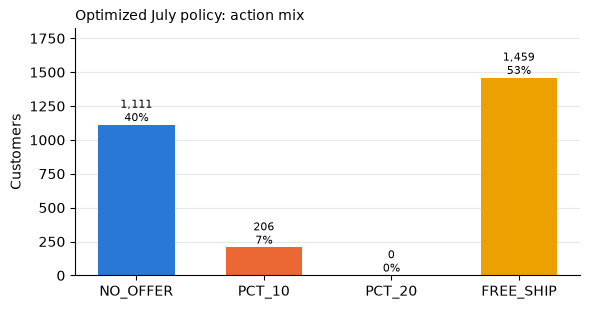

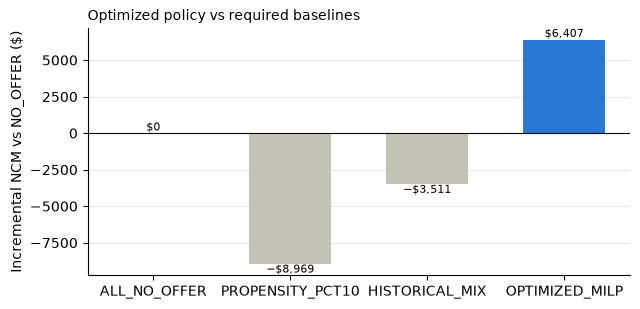

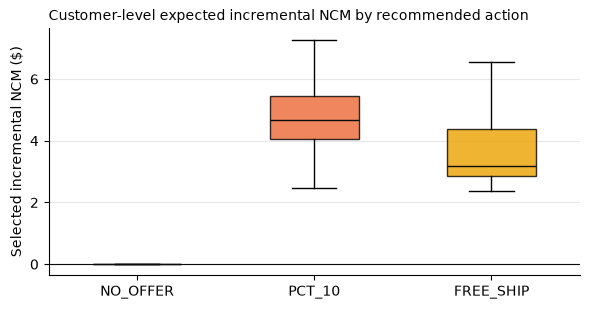

In [6]:
def style(a):
    a.spines[["top", "right"]].set_visible(False); a.grid(axis="y", alpha=0.3); a.set_axisbelow(True)
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(ACTIONS, act.customers, color=[COLORS[a] for a in ACTIONS], width=0.6)
for i, (c, s) in enumerate(zip(act.customers, act.share)):
    ax.text(i, c, f"{c:,}\n{s:.0%}", ha="center", va="bottom", fontsize=8)
ax.set_ylabel("Customers"); ax.set_title("Optimized July policy: action mix", loc="left", fontsize=10); ax.set_ylim(0, act.customers.max() * 1.25); style(ax)
fig.tight_layout(); fig.savefig(FIGS / "10_optimized_action_mix.png", dpi=130, bbox_inches="tight"); plt.show()
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.bar(cmp.policy, cmp.total_expected_incremental_ncm, color=["#c3c2b7", "#c3c2b7", "#c3c2b7", "#2a78d6"], width=0.6)
ax.axhline(0, color="#0b0b0b", lw=0.8)
for i, v in enumerate(cmp.total_expected_incremental_ncm):
    ax.text(i, v, f"{'−' if v < 0 else ''}${abs(v):,.0f}", ha="center", va="bottom" if v >= 0 else "top", fontsize=8)
ax.set_ylabel("Incremental NCM vs NO_OFFER ($)"); ax.set_title("Optimized policy vs required baselines", loc="left", fontsize=10); style(ax)
fig.tight_layout(); fig.savefig(FIGS / "10_baseline_comparison.png", dpi=130, bbox_inches="tight"); plt.show()
fig, ax = plt.subplots(figsize=(6, 3.2))
data = [pol.loc[pol.recommended_action == a, "estimated_incremental_ncm"] for a in ACTIONS if (pol.recommended_action == a).any()]
labs = [a for a in ACTIONS if (pol.recommended_action == a).any()]
bp = ax.boxplot(data, tick_labels=labs, patch_artist=True, showfliers=False, widths=0.5, medianprops={"color": "#0b0b0b"})
for patch, a in zip(bp["boxes"], labs):
    patch.set_facecolor(COLORS[a]); patch.set_alpha(0.8)
ax.axhline(0, color="#0b0b0b", lw=0.8); ax.set_ylabel("Selected incremental NCM ($)")
ax.set_title("Customer-level expected incremental NCM by recommended action", loc="left", fontsize=10); style(ax)
fig.tight_layout(); fig.savefig(FIGS / "10_selected_incremental_by_action.png", dpi=130, bbox_inches="tight"); plt.show()

## Output paths

In [7]:
for p in ["policy_submission.csv", "outputs/final/policy_submission.csv", "outputs/tables/baseline_policy_comparison.csv",
          "outputs/tables/baseline_policy_assignments.csv", "outputs/tables/final_policy_summary.csv", "outputs/tables/policy_action_summary.csv",
          "outputs/tables/customer_policy_audit.csv", "outputs/figures/10_optimized_action_mix.png", "outputs/figures/10_baseline_comparison.png",
          "outputs/figures/10_selected_incremental_by_action.png"]:
    assert (ROOT / p).exists(), p
    print(" ", p)

  policy_submission.csv
  outputs/final/policy_submission.csv
  outputs/tables/baseline_policy_comparison.csv
  outputs/tables/baseline_policy_assignments.csv
  outputs/tables/final_policy_summary.csv
  outputs/tables/policy_action_summary.csv
  outputs/tables/customer_policy_audit.csv
  outputs/figures/10_optimized_action_mix.png
  outputs/figures/10_baseline_comparison.png
  outputs/figures/10_selected_incremental_by_action.png
